C:\Users\darsh\AppData\Local\Temp\ipykernel_8420\192468108.py:86: RuntimeWarning: invalid value encountered in cast
  y_test_pred = np.round(lr_model.predict(X_test_scaled)).astype(int)


Train accuracy: 87.67%
Test accuracy: 20.12%
Classification Report:
                  precision    recall  f1-score   support

       Apple_Bad       0.30      0.53      0.39       201
      Apple_Good       0.09      0.06      0.07       201
      Banana_Bad       0.21      0.15      0.17       210
     Banana_Good       0.23      0.20      0.21       216
       Guava_Bad       0.17      0.16      0.16       200
      Guava_Good       0.12      0.10      0.11       208
        Lime_Bad       0.09      0.10      0.10       186
       Lime_Good       0.18      0.21      0.19       195
      Orange_Bad       0.16      0.17      0.16       187
     Orange_Good       0.13      0.11      0.12       185
 Pomegranate_Bad       0.21      0.12      0.15       222
Pomegranate_Good       0.33      0.54      0.41       189

        accuracy                           0.20      2400
       macro avg       0.18      0.20      0.19      2400
    weighted avg       0.19      0.20      0.19      2400



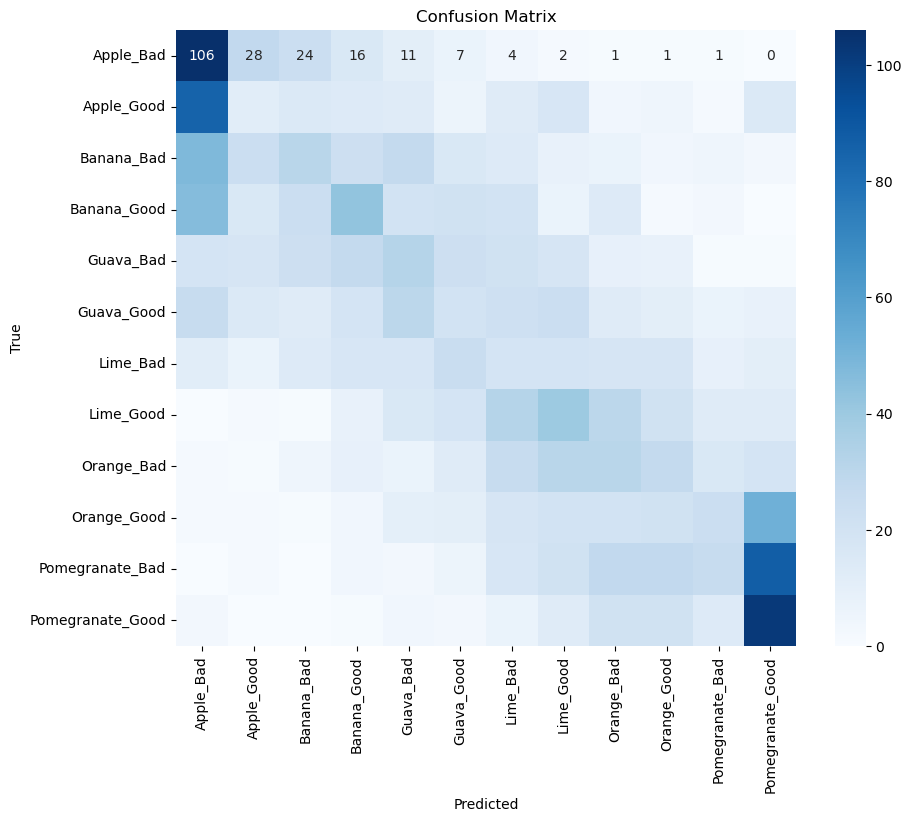

The predicted class for the image is: Apple_Bad


C:\Users\darsh\AppData\Local\Temp\ipykernel_8420\192468108.py:124: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predicted_label_index = np.clip(int(np.round(prediction)), 0, len(label_encoder.classes_) - 1)


In [ ]:
import os
import numpy as np
import cv2
from skimage.feature import hog
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def extract_features(image, img_size=128):
    # Resize image
    image = cv2.resize(image, (img_size, img_size))
    
    # Extract color histogram (normalized)
    hist = cv2.calcHist([image], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    
    # Convert image to grayscale for HOG
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Extract HOG features
    hog_features, hog_image = hog(gray_image, pixels_per_cell=(8, 8), cells_per_block=(2, 2), 
                                  visualize=True, feature_vector=True)
    
    # Extract mean color
    mean_color = cv2.mean(image)[:3]  # Ignore the alpha channel if present
    
    # Combine all features
    features = np.hstack([hist, hog_features, mean_color])
    
    return features

def load_data(data_dir, img_size=128):
    data = []
    labels = []
    valid_extensions = ['.jpg', '.jpeg', '.png']  # Valid image extensions
    
    for root, dirs, files in os.walk(data_dir):
        for dir_name in dirs:
            category_path = os.path.join(root, dir_name)
            label = dir_name  # Folder name used as label
            for img in os.listdir(category_path):
                try:
                    img_path = os.path.join(category_path, img)
                    
                    # Check if the file has a valid image extension
                    if os.path.splitext(img_path)[1].lower() not in valid_extensions:
                        continue  # Skip non-image files
                    
                    img_array = cv2.imread(img_path, cv2.IMREAD_COLOR)
                    if img_array is not None:
                        features = extract_features(img_array, img_size)
                        data.append(features)
                        labels.append(label)
                    else:
                        print(f"Warning: Failed to load image {img_path}")
                except Exception as e:
                    print(f"Error loading image {img_path}: {e}")
    return np.array(data), np.array(labels)

# Load data
data_dir = r"//folder path"
X, y = load_data(data_dir)

# Encode labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Predict and map the regression outputs to class labels
y_train_pred = np.round(lr_model.predict(X_train_scaled)).astype(int)
y_test_pred = np.round(lr_model.predict(X_test_scaled)).astype(int)

# Clip predictions to be within the valid range of class labels
y_train_pred = np.clip(y_train_pred, 0, len(label_encoder.classes_) - 1)
y_test_pred = np.clip(y_test_pred, 0, len(label_encoder.classes_) - 1)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f'Train accuracy: {train_accuracy*100:.2f}%')
print(f'Test accuracy: {test_accuracy*100:.2f}%')

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=label_encoder.classes_))

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

def predict_sample_image(image_path, model, label_encoder, scaler, img_size=128):
    img_array = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if img_array is None:
        print(f"Error: Unable to load image at {image_path}")
        return
    
    features = extract_features(img_array, img_size)
    features_scaled = scaler.transform(features.reshape(1, -1))
    
    prediction = model.predict(features_scaled)
    predicted_label_index = np.clip(int(np.round(prediction)), 0, len(label_encoder.classes_) - 1)
    predicted_label = label_encoder.inverse_transform([predicted_label_index])
    
    print(f"The predicted class for the image is: {predicted_label[0]}")

# Path to a sample image for prediction
sample_image_path = r"// image path"

# Predict the quality of the sample image
predict_sample_image(sample_image_path, lr_model, label_encoder, scaler)
